# 학습 영상 전처리 및 증강 검토

## 목적 및 범위
학습용 고정 표본에서 크기 축소와 국소 대비 조정이 영상 표현에 미치는 영향을 비교한다. 모델 성능이나 임상적 판독 정확성의 개선 여부는 평가하지 않는다. 검증·테스트 영상은 표본 선택이나 시각 검토에 사용하지 않는다.

비교 조건은 원본, Resize만 적용, 원본 해상도에서 CLAHE 후 Resize 적용의 세 가지다. 현재 기본 전처리는 CLAHE 미적용 상태로 유지한다.

## 방법
- 표본: 선행 학습용 검토 목록의 고정 행 0/1/6/10, 총 4장. 양성 라벨 2장·음성 라벨 2장, L 및 RGBA 입력을 포함한다. 대표성을 확보한 무작위 표본은 아니다.
- CLAHE: OpenCV 4.13.0, `clipLimit=2.0`, `tileGridSize=(8,8)`. 격자는 8픽셀 크기가 아니라 가로·세로 영역의 개수다. 설정은 비교 조건이며 최적값으로 추정하지 않았다.
- 순서: 원본을 8비트 흑백으로 변환 → CLAHE → RGB 3채널 → 224×224 bilinear 축소 → 텐서 → ImageNet 정규화.
- 그림에는 정규화 전 영상을 사용하고 모든 패널에 동일한 밝기 표시 범위 0–255를 적용한다. 잘라내기는 적용하지 않는다. 패널의 표시 크기는 같지만 실제 배열 해상도는 원본 1024×1024, 처리 결과 224×224다.

## 출처
데이터 제공: NIH Clinical Center. [NIH 원본 배포처](https://nihcc.app.box.com/v/ChestXray-NIHCC), [Kaggle 배포본](https://www.kaggle.com/datasets/nih-chest-xrays/data).

방법과 API: [OpenCV CLAHE 설명](https://docs.opencv.org/4.13.0/d5/daf/tutorial_py_histogram_equalization.html), [OpenCV CLAHE API](https://docs.opencv.org/4.13.0/d6/db6/classcv_1_1CLAHE.html). 분석 코드는 프로젝트의 `src/preprocessing.py`와 `scripts/compare_preprocessing.py`에 구현한다.

## 1. 실행 환경
프로젝트 가상환경을 사용한다. `PROJECT_ROOT`를 지정하지 않으면 현재 위치의 상위 경로에서 프로젝트를 탐색한다. 실행 시 비교 그림과 결과 표를 다시 생성하며 원본 영상과 분할 목록은 변경하지 않는다.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = None
if PROJECT_ROOT is None:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/raw/Data_Entry_2017.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("PROJECT_ROOT에 프로젝트 경로 지정 필요")
ROOT = Path(PROJECT_ROOT).resolve()
sys.path.insert(0, str(ROOT))
from scripts.compare_preprocessing import run_comparison
result = run_comparison()
print("비교 분석 완료: 학습 표본 4장, 원본 변경 없음")

비교 분석 완료: 학습 표본 4장, 원본 변경 없음


## 2. 비교 영상
원본과 축소 결과를 동일한 패널 크기로 표시하므로 축소 결과의 부드러움과 세부 표현 차이가 보일 수 있다. CLAHE는 영상 가장자리, 문자, 기기 표식에도 작용하며 폐 영역만을 선택적으로 처리하는 방법이 아니다.

,Image Index,Finding Labels,pneumonia,mode
0,00014234_000.png,Pneumonia,1,L
1,00013249_034.png,Cardiomegaly|Edema|Infiltration|Pneumonia,1,L
2,00003083_001.png,Effusion,0,L
3,00000917_000.png,No Finding,0,RGBA


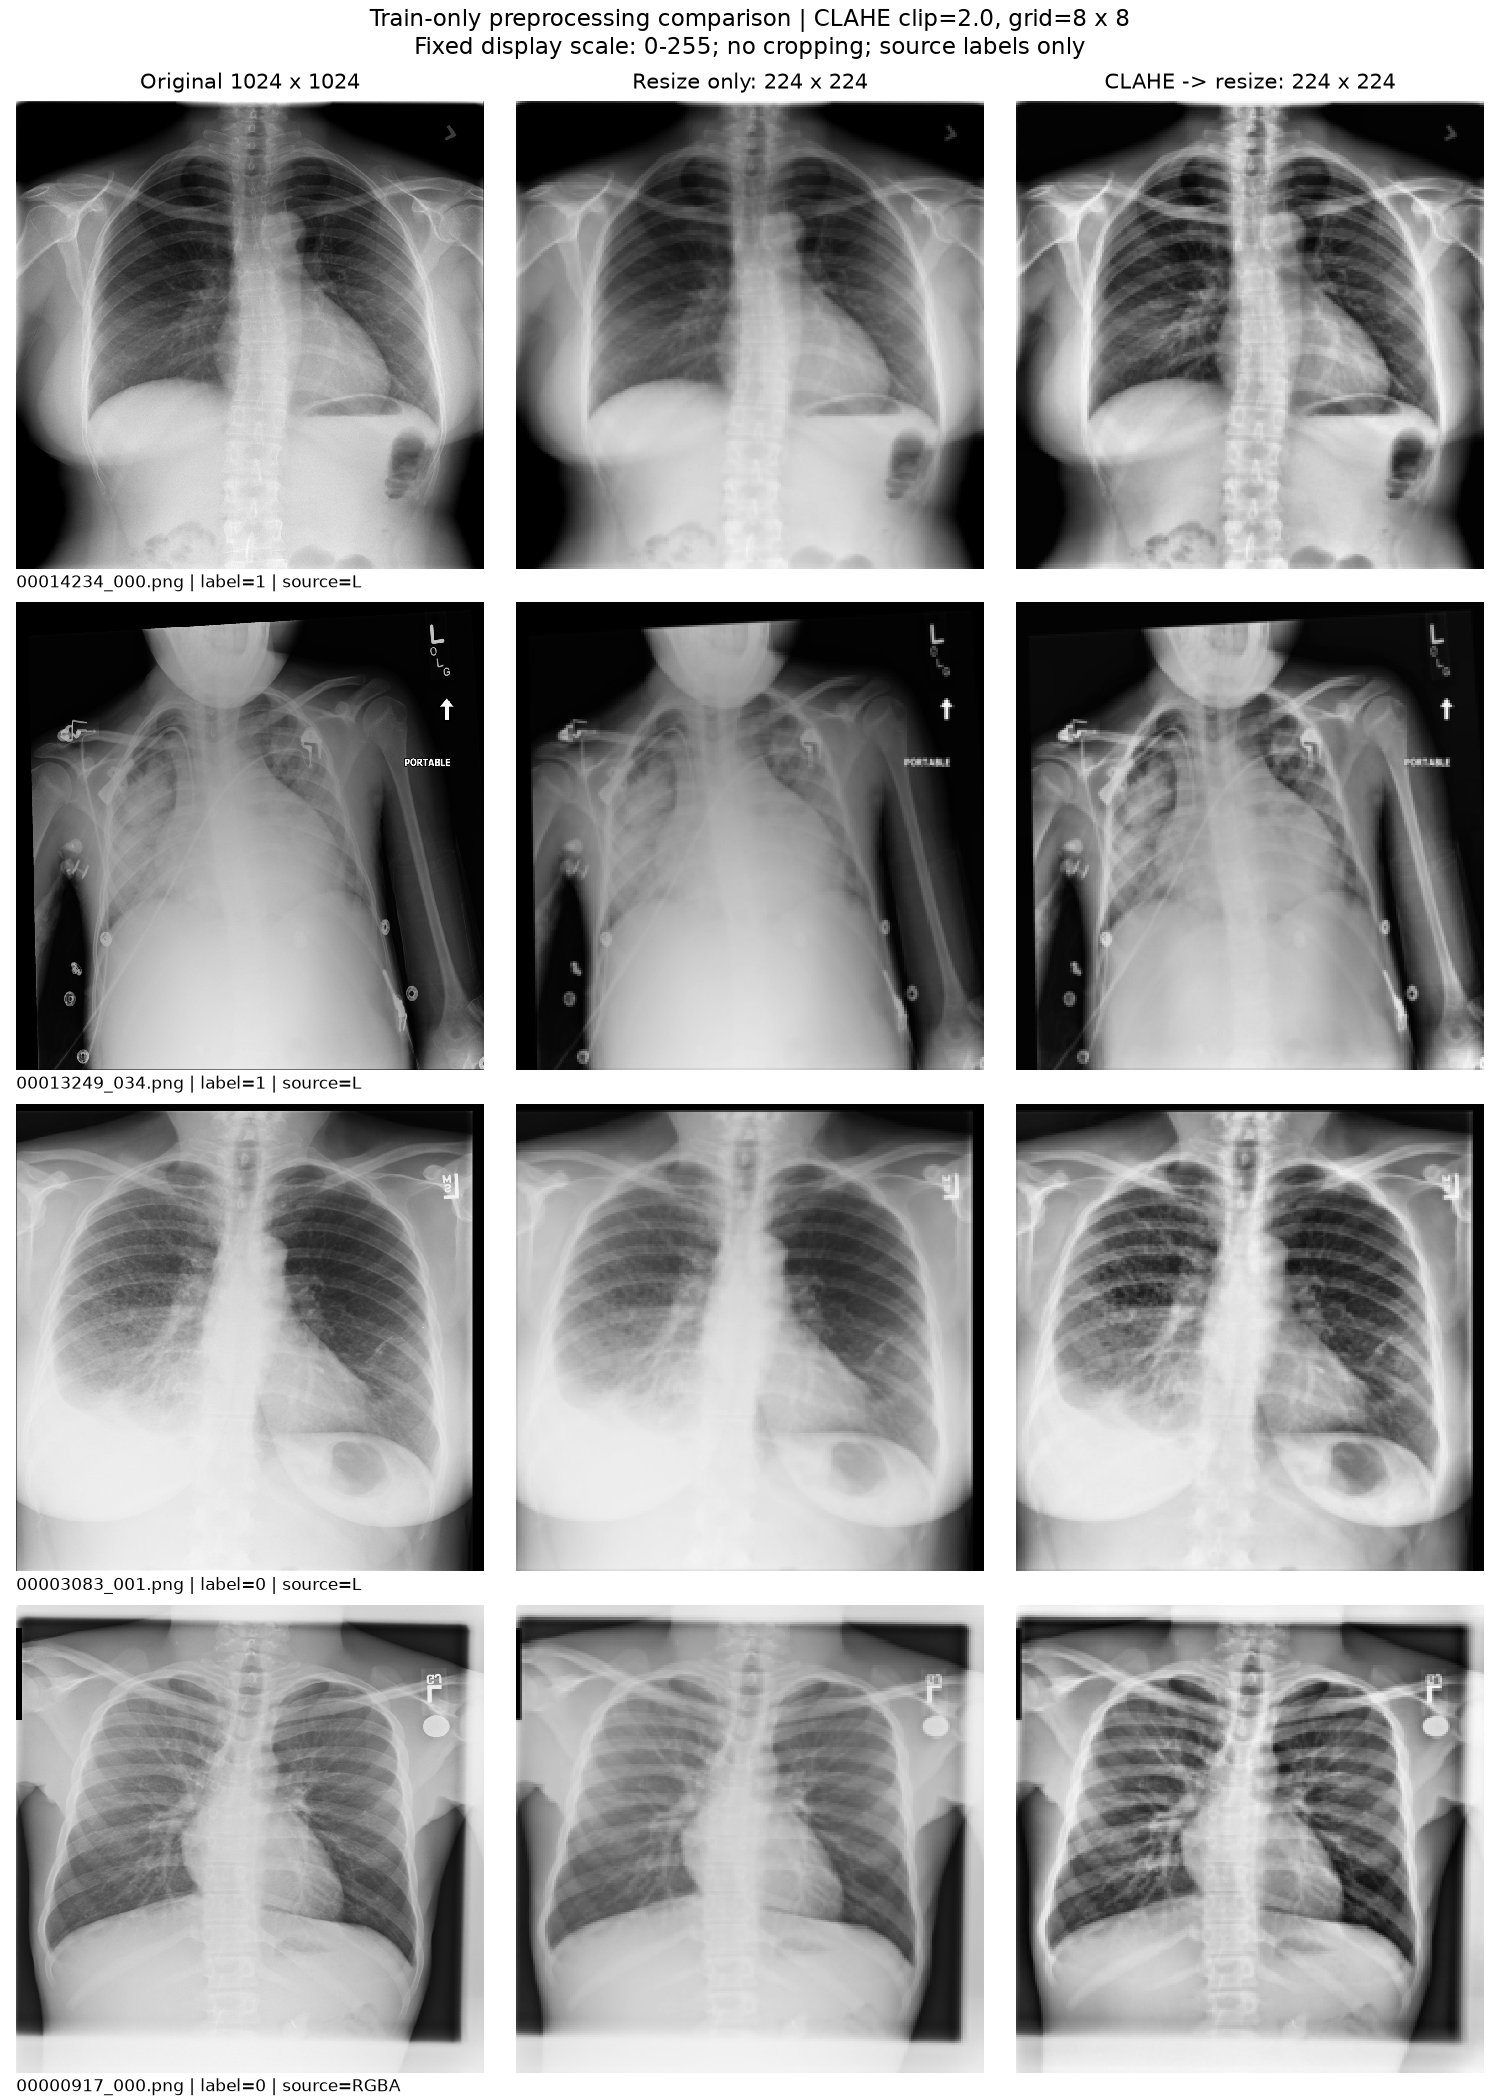

In [2]:
samples = pd.read_csv(ROOT / "outputs/metrics/preprocessing/comparison_samples.csv")
display(samples[["Image Index", "Finding Labels", "pneumonia", "mode"]])
display(Image(filename=str(result["figure"])))

## 3. 영상 수치와 반복 적용 검증
밝기 평균·표준편차와 백분위수는 변환의 영향을 기술하기 위해 기록한다. 값이 커지거나 명암이 강조되는 것을 화질 또는 질환 분류 성능의 개선으로 해석하지 않는다.

평가용 전처리에 필요한 반복 적용 결정성, 출력 크기, 유한 수치와 원본 파일 해시 보존을 확인한다. 정규화 후 평균·표준편차가 정확히 0·1이 될 필요는 없다. ImageNet 통계와 이 표본의 밝기 분포가 다르기 때문이다.

In [3]:
display(result["table"].round(3))
checks = result["checks"]
display(pd.DataFrame([checks["checks"]]))
display(pd.DataFrame(checks["normalized_batch_statistics"])[["variant", "batch_shape", "normalized_batch_mean", "normalized_batch_std"]])
print("기본 전처리:", checks["baseline_default"])
print("모델 성능 개선 검증:", checks["quality_or_model_improvement_established"])

,image,pneumonia_label,source_mode,variant,width,height,mean_intensity,std_intensity,p01,p99,zero_pixel_percent,max_pixel_percent
0,00014234_000.png,1,L,Original 1024 x 1024,1024,1024,122.195,72.245,0.0,229.00,10.267,0.019
1,00014234_000.png,1,L,Resize only: 224 x 224,224,224,122.173,72.023,0.0,228.00,9.859,0.000
2,00014234_000.png,1,L,CLAHE -> resize: 224 x 224,224,224,125.106,70.295,2.0,234.00,0.000,0.000
3,00013249_034.png,1,L,Original 1024 x 1024,1024,1024,98.680,75.270,0.0,226.00,8.350,0.054
4,00013249_034.png,1,L,Resize only: 224 x 224,224,224,98.704,74.815,0.0,226.00,7.659,0.000
5,00013249_034.png,1,L,CLAHE -> resize: 224 x 224,224,224,108.728,72.732,2.0,219.25,0.000,0.000
6,00003083_001.png,0,L,Original 1024 x 1024,1024,1024,160.549,67.119,0.0,238.00,3.870,0.000
7,00003083_001.png,0,L,Resize only: 224 x 224,224,224,160.598,66.671,0.0,238.00,3.181,0.000
8,00003083_001.png,0,L,CLAHE -> resize: 224 x 224,224,224,154.228,66.056,2.0,236.00,0.000,0.000
9,00000917_000.png,0,RGBA,Original 1024 x 1024,1024,1024,160.555,55.324,22.0,241.00,0.229,0.000


,training_membership,finite_3x224x224_tensors,repeat_evaluation_deterministic,source_file_hashes_unchanged
0,True,True,True,True


,variant,batch_shape,normalized_batch_mean,normalized_batch_std
0,resize_only,"[4, 3, 224, 224]",0.365506,1.267231
1,clahe_then_resize,"[4, 3, 224, 224]",0.358205,1.231224


기본 전처리: resize_only; unchanged
모델 성능 개선 검증: False


## 4. 관찰 결과와 적용 상태

### 관찰
- Resize는 전체 촬영 범위를 유지하면서 세부 표현을 줄인다. 문자와 기기 표식을 자동 제거하는 처리가 아니다.
- 이 네 표본에서 CLAHE는 국소적인 밝기 차이와 경계 표현을 바꾼다. 일부 문자·표식과 폐 밖 구조도 함께 강조된다.
- L·RGBA 입력 모두 출력 `(3,224,224)` 및 유한 수치 검사를 통과했다. 같은 입력의 반복 처리 결과는 일치했고 원본 파일 해시는 유지되었다.

### 적용 상태
CLAHE는 `build_transform(use_clahe=True)`로 선택 가능하게 구현했다. 현재 기본값은 `False`다. CLAHE를 채택할 경우 학습·검증·테스트에 같은 조건을 적용해야 하며, 테스트 성능을 보고 적용 여부나 파라미터를 선택하지 않는다.

### 한계 및 후속 작업
4장의 편의 표본으로 전체 영상의 변환 적합성이나 임상적 정보 보존을 판단할 수 없다. CLAHE 사용 여부에 따른 모델 성능 비교는 아직 수행하지 않았다. 아래에서는 CLAHE를 끈 상태에서 학습용 약한 증강을 별도 검토한다. CLAHE 적용 여부에 따른 모델 성능 비교와 모델 학습은 수행하지 않는다.

## 5. 학습용 증강 조건

학습 전용 후보 변환으로 약한 회전과 밝기·대비 조정을 구현한다. 조건은 최적값을 추정한 결과가 아니라 시각 검토를 위한 초기 설정이다.

| 변환 | 적용 조건 |
|---|---|
| 회전 | 확률 0.5, 각도 -5~+5도, bilinear 보간, 출력 크기 유지, 빈 영역 0으로 채움 |
| 밝기·대비 | 확률 0.5로 조정 묶음 적용, 각 계수 0.9~1.1 범위 |
| CLAHE | 이번 증강 비교에서는 미적용 |
| 뒤집기·임의 Crop·노이즈·가림 | 미적용 |

순서: RGB 변환 → 224×224 축소 → 학습 전용 증강 → 텐서 → 정규화. 평가용에는 증강을 제외한다. 두 무작위 적용 단계가 모두 생략되면 일부 결과는 평가용 입력과 같을 수 있다.

회전은 캔버스 크기를 유지하므로 테두리에 검은 부분이 생기고 가장자리 일부가 손실될 수 있다. 약한 각도라도 진단 정보 보존을 보장하지 않는다. 데이터 증강은 문자를 제거하거나 라벨 노이즈를 해결하는 방법이 아니다.

구현 API: [Torchvision RandomRotation](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.RandomRotation.html), [ColorJitter](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.ColorJitter.html).

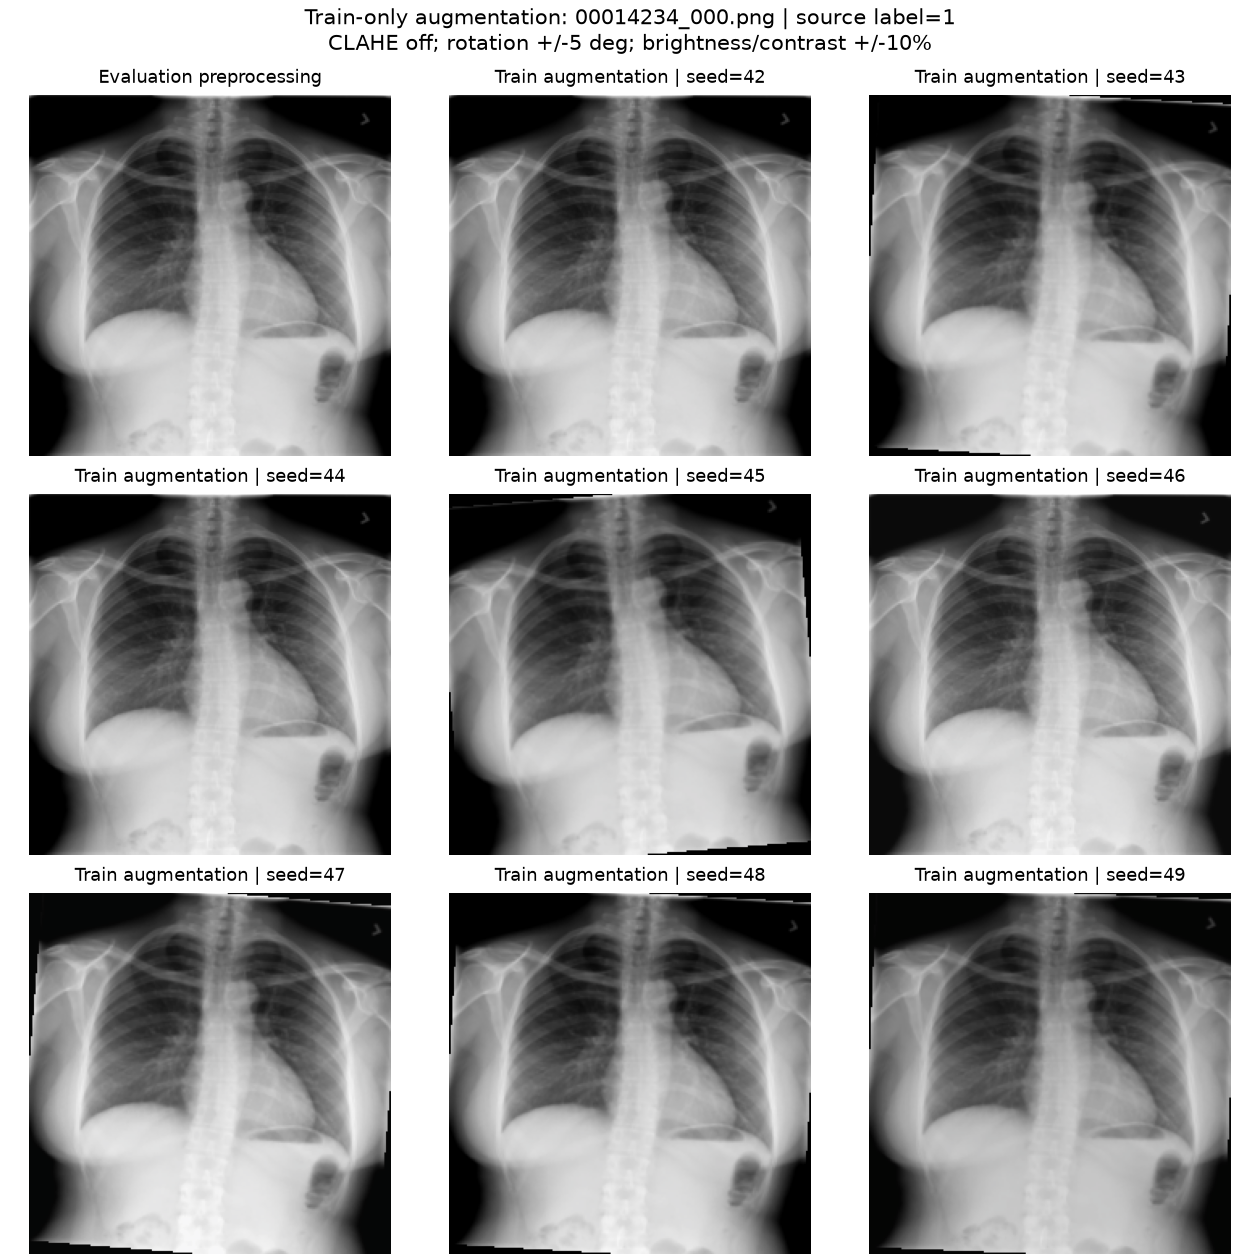

In [4]:
from scripts.preview_augmentation import run_review
augmentation = run_review()
display(Image(filename=str(augmentation["repeated_figure"])))

## 6. 실제 배치 및 평가 결정성 검증

기존 학습 목록의 L·RGBA 영상 4장을 Dataset과 DataLoader로 읽는다. 이진 라벨과 목록의 일치, 유한 수치와 `(4,3,224,224)` 출력 크기를 확인한다.

같은 원본의 평가용 변환을 반복해 동일한 텐서가 생성되는지 검증한다. 증강을 끈 학습용 변환은 평가용 변환과 일치해야 한다. 시각화에서는 재현을 위해 난수 시드 42~49를 기록하며, 실제 학습에서 매 영상마다 같은 시드를 다시 설정하는 방식은 사용하지 않는다.

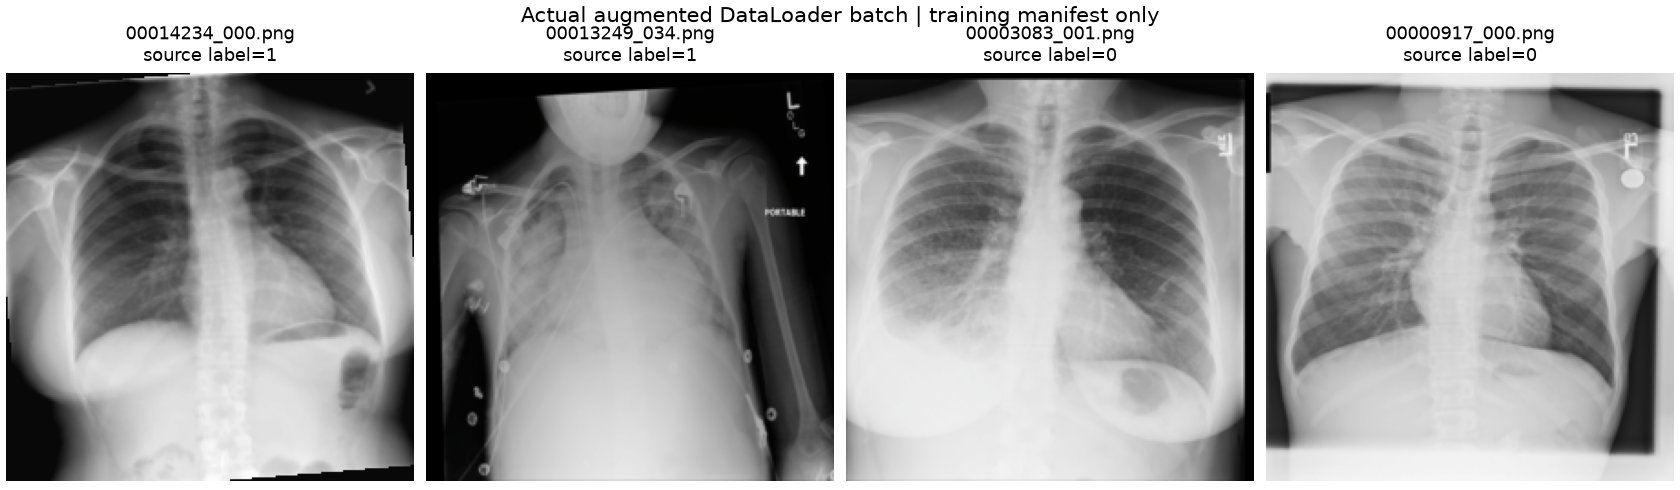

,passed
sample_membership_in_training,True
original_files_unchanged,True
evaluation_deterministic,True
evaluation_matches_previous_baseline,True
augmentation_off_matches_evaluation,True
seed_reproducible,True
training_output_varies,True
finite_3x224x224_output,True
actual_loader_labels_match_manifest,True


실제 입력 묶음: [4, 3, 224, 224]
정규화 후 표본 평균: 0.4086
정규화 후 표본 표준편차: 1.2713


In [5]:
display(Image(filename=str(augmentation["batch_figure"])))
display(pd.DataFrame([augmentation["checks"]["checks"]]).T.rename(columns={0: "passed"}))
print("실제 입력 묶음:", augmentation["checks"]["actual_batch_shape"])
print("정규화 후 표본 평균:", round(augmentation["checks"]["normalized_batch_mean"], 4))
print("정규화 후 표본 표준편차:", round(augmentation["checks"]["normalized_batch_std"], 4))

## 7. 증강 검토 결과 및 사용 상태

4장 각각에 8개의 시드 조건을 적용하여 입력의 변화와 고정 시드의 재현성을 확인했다. 실제 배치의 라벨 대응, 평가 변환의 결정성, 원본 해시 보존을 확인했다. 표본 그림에서는 회전에 의한 검은 테두리와 작은 자세 변화, 밝기·대비 차이가 관찰된다.

`build_train_transform()`은 증강이 있는 학습 입력, `build_eval_transform()`은 무작위 변환이 없는 평가 입력을 구성한다. `build_train_transform(augment=False)`로 증강을 끌 수 있다. 기존 `build_transform()`은 결정적인 기준 전처리로 유지하며 기존 속도 측정 코드는 아직 증강 없는 설정을 사용한다. 본 학습에 사용할 조합은 별도 학습 설정에서 명시해야 한다.

원본 이미지와 학습 목록의 개수는 증가하지 않는다. 증강 영상은 입력을 읽을 때 메모리에서 생성되며 별도 학습용 파일로 일괄 저장하지 않았다. 증강의 성능 개선 여부와 전체 영상에 대한 적합성은 아직 평가하지 않았다.

후속 작업은 1주차 산출물과 README의 현재 상태를 점검하고, 첫 본 학습의 전처리·증강 조건을 명시하는 것이다. 이 노트북은 모델 학습이나 테스트 성능 평가를 수행하지 않는다.